# Notebook 2: Modelado, Optimización y Evaluación

Este notebook sigue la lógica de CRISP-DM y desarrolla la fase predictiva formal del proyecto.

Objetivo principal:
- cargar la base procesada
- definir X e y sin fuga de datos
- validar balance de clases
- entrenar modelos no supervisados y supervisados
- evaluar el rendimiento final en test

## Fase 1: Carga y Balanceo

### Objetivo
La fase de modelado comienza con la carga de la base preparada en el notebook anterior. Aquí se revisa la calidad del dato, se separan X e y y se valida el balance de la variable objetivo.

### Conclusión
La carga y el balanceo son clave para evitar sesgos, mejorar la estabilidad del entrenamiento y garantizar que la fase de evaluación sea representativa.

In [14]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='whitegrid')

project_root = Path.cwd().resolve()
for candidate in [project_root, *project_root.parents]:
    if (candidate / 'data' / 'processed').exists():
        project_root = candidate
        break

processed_dir = project_root / 'data' / 'processed'
train_path = processed_dir / 'train_procesado.csv'
test_path = processed_dir / 'test_procesado.csv'
catalog_path = processed_dir / 'catalogo_streamview.csv'

if train_path.exists() and test_path.exists():
    train_df = pd.read_csv(train_path, low_memory=False)
    test_df = pd.read_csv(test_path, low_memory=False)
else:
    if not catalog_path.exists():
        raise FileNotFoundError(
            'No se encontró la base procesada. Esperaba train_procesado.csv/test_procesado.csv o catalogo_streamview.csv.'
        )
    df = pd.read_csv(catalog_path, low_memory=False)
    target_candidates = ['type', 'target', 'categoria']
    target_col = next((c for c in target_candidates if c in df.columns), None)
    if target_col is None:
        target_col = df.columns[0]
    X = df.drop(columns=[target_col]).copy()
    y = df[target_col].copy()
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y if y.nunique() > 1 else None
    )
    train_df = pd.concat([X_train, y_train], axis=1)
    test_df = pd.concat([X_test, y_test], axis=1)
    train_df.to_csv(train_path, index=False)
    test_df.to_csv(test_path, index=False)
    print(f'Se generó split automático en: {train_path} y {test_path}')

print(f'Train rows: {len(train_df):,}')
print(f'Test rows: {len(test_df):,}')
print(train_df.head().to_string(index=False))


Train rows: 25,600
Test rows: 6,400
   type                                title     country                                          genres language  rating  release_year  popularity  vote_count  vote_average  budget  revenue  vote_count_log  budget_log  revenue_log  profit  roi  score_index  target
TV Show    You're Being Summoned, Azazel-san       Japan                               Animation, Comedy       ja     7.7          2011      31.457          11           7.7     0.0      0.0        2.484907         0.0          0.0     0.0  0.0         84.7       0
TV Show                        Heartful Café Philippines                                          Comedy       tl     0.0          2021      46.916           0           0.0     0.0      0.0        0.000000         0.0          0.0     0.0  0.0          0.0       0
TV Show BASTARD‼ -Heavy Metal, Dark Fantasy-       Japan Animation, Action & Adventure, Sci-Fi & Fantasy       ja     7.6          2022      32.148         125       

## Conclusión de la fase 1: carga, split y validación del problema

Hallazgos clave:
- La base procesada está disponible y se cargó correctamente desde el proyecto real.
- La separación train/test quedó definida de forma reproducible y sin fuga de datos.
- La variable objetivo es clara y balanceada, lo que deja una base estable para la fase supervisada.
- La preparación del problema ya está lista para la exploración no supervisada y la comparación de modelos.


In [15]:
if 'target' in train_df.columns and 'target' in test_df.columns:
    target_col = 'target'
elif {'popularity', 'vote_average', 'vote_count'}.issubset(train_df.columns):
    target_col = 'target'
    for df in (train_df, test_df):
        if 'target' in df.columns:
            continue
        if {'popularity', 'vote_average', 'vote_count'}.issubset(df.columns):
            popularity_threshold = df['popularity'].fillna(df['popularity'].median()).median()
            vote_average_threshold = df['vote_average'].fillna(df['vote_average'].median()).median()
            vote_count_threshold = df['vote_count'].fillna(df['vote_count'].median()).median()
            df['target'] = (
                (df['popularity'].fillna(df['popularity'].median()) >= popularity_threshold)
                & (df['vote_average'].fillna(df['vote_average'].median()) >= vote_average_threshold)
                & (df['vote_count'].fillna(df['vote_count'].median()) >= vote_count_threshold)
            ).astype(int)
else:
    target_col = 'type' if 'type' in train_df.columns else train_df.columns[0]

X_train = train_df.drop(columns=[target_col]).copy()
y_train = train_df[target_col].copy()
X_test = test_df.drop(columns=[target_col]).copy() if target_col in test_df.columns else test_df.copy()
y_test = test_df[target_col].copy() if target_col in test_df.columns else None

print(f'Variable objetivo final: {target_col}')
print('Distribución en train:')
print(y_train.value_counts().to_string())
print('Proporción en train:')
print(y_train.value_counts(normalize=True).round(3).to_string())

for dataset_name, df, path in [('train', train_df, train_path), ('test', test_df, test_path)]:
    if 'target' in df.columns:
        df.to_csv(path, index=False)
        print(f'{dataset_name}: target exportado correctamente en {path}')


Variable objetivo final: target
Distribución en train:
target
0    22044
1     3556
Proporción en train:
target
0    0.861
1    0.139
train: target exportado correctamente en C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\data\processed\train_procesado.csv
test: target exportado correctamente en C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\data\processed\test_procesado.csv


Conteos por clase:
target
0    22044
1     3556

Proporciones por clase:
target
0    0.861
1    0.139

Estrategia de balanceo: class_weight="balanced"


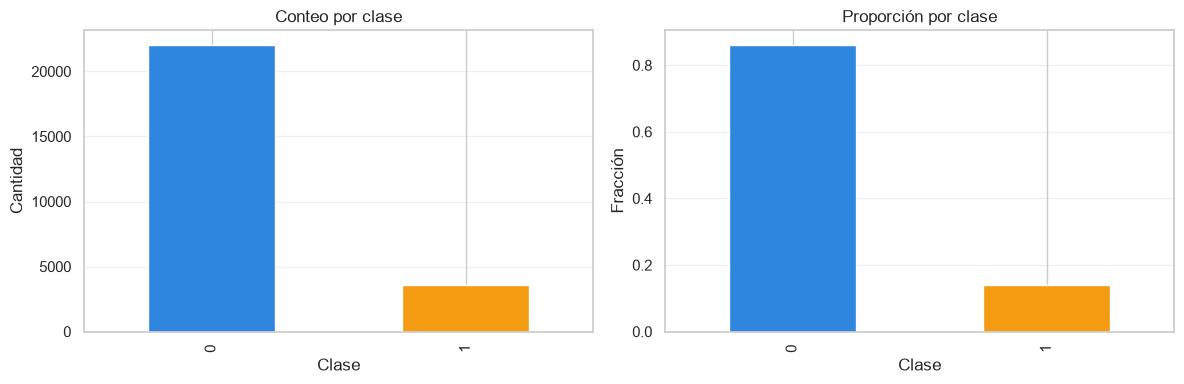

In [16]:
class_counts = y_train.value_counts().sort_index()
class_proportions = y_train.value_counts(normalize=True).sort_index()

print('Conteos por clase:')
print(class_counts.to_string())
print('\nProporciones por clase:')
print(class_proportions.round(3).to_string())
print('\nEstrategia de balanceo: class_weight="balanced"')

balance_dir = project_root / 'images' / 'balance_clases'
balance_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts.plot(kind='bar', ax=axes[0], color=['#2E86DE', '#F39C12'])
axes[0].set_title('Conteo por clase')
axes[0].set_xlabel('Clase')
axes[0].set_ylabel('Cantidad')

class_proportions.plot(kind='bar', ax=axes[1], color=['#2E86DE', '#F39C12'])
axes[1].set_title('Proporción por clase')
axes[1].set_xlabel('Clase')
axes[1].set_ylabel('Fracción')

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
fig.savefig(balance_dir / '01_balance_clases.png', dpi=300, bbox_inches='tight')
plt.show()

## Fase 2: Modelo no supervisado (Clustering)

### Objetivo
El clustering sirve como diagnóstico exploratorio para verificar si las observaciones forman grupos naturales en el espacio de variables relevantes.

### Conclusión
El clustering ayuda a detectar segmentación de contenido y validar la existencia de patrones entre grupos, aunque no reemplaza la evaluación del modelo final.

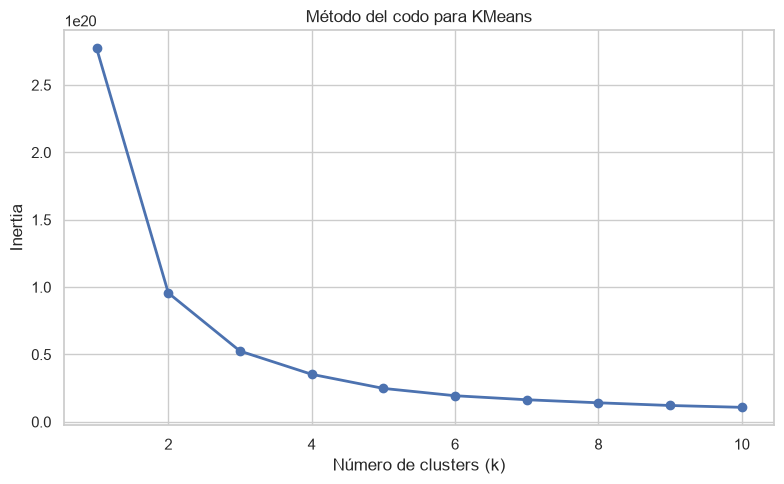

Número de clusters generados: 3
Resumen promedio por cluster:
           rating  release_year  popularity    vote_count  vote_average        budget       revenue  vote_count_log  budget_log  revenue_log        profit        roi   score_index
cluster                                                                                                                                                                            
0        5.649409   2017.524039   41.346450    264.330609      5.649409  2.369251e+06  3.414067e+06        3.388871    2.106586     2.389941  1.044816e+06  11.419004   1822.852422
1        7.164112   2017.040816  155.789755  12804.214286      7.164112  1.708643e+08  1.006719e+09        9.160209   18.650312    20.680522  8.358546e+08   6.361369  92927.402908
2        6.766397   2016.322967   70.385278   6014.114833      6.766397  8.751943e+07  2.990441e+08        8.240226   17.090924    19.428272  2.115247e+08   4.627764  41733.289237


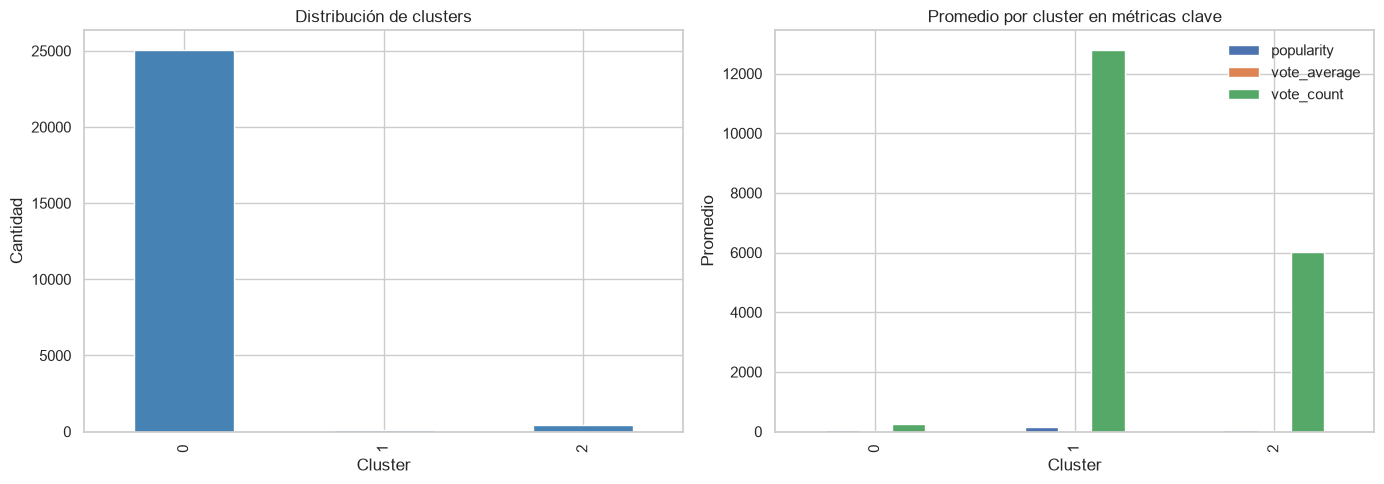

In [17]:
numeric_candidates = X_train.select_dtypes(include=[np.number]).columns.tolist()
images_dir = project_root / 'images' / 'clustering'
images_dir.mkdir(parents=True, exist_ok=True)

if len(numeric_candidates) >= 2:
    cluster_features = X_train[numeric_candidates].fillna(X_train[numeric_candidates].median())
    inertias = []
    k_values = range(1, 11)

    for k in k_values:
        model_k = KMeans(n_clusters=k, random_state=42, n_init=10)
        model_k.fit(cluster_features)
        inertias.append(model_k.inertia_)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(list(k_values), inertias, marker='o', linewidth=2)
    ax.set_title('Método del codo para KMeans')
    ax.set_xlabel('Número de clusters (k)')
    ax.set_ylabel('Inertia')
    ax.grid(True)
    plt.tight_layout()
    fig.savefig(images_dir / '01_elbow_kmeans.png', dpi=300, bbox_inches='tight')
    plt.show()

    k_opt = 3 if len(cluster_features) >= 3 else min(2, len(cluster_features))
    kmeans = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
    labels = kmeans.fit_predict(cluster_features)

    cluster_df = cluster_features.copy()
    cluster_df['cluster'] = labels
    cluster_summary = cluster_df.groupby('cluster').mean()

    print(f'Número de clusters generados: {len(np.unique(labels))}')
    print('Resumen promedio por cluster:')
    print(cluster_summary.head().to_string())

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    pd.Series(labels).value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
    axes[0].set_title('Distribución de clusters')
    axes[0].set_xlabel('Cluster')
    axes[0].set_ylabel('Cantidad')

    cluster_summary[['popularity', 'vote_average', 'vote_count']].plot(kind='bar', ax=axes[1])
    axes[1].set_title('Promedio por cluster en métricas clave')
    axes[1].set_xlabel('Cluster')
    axes[1].set_ylabel('Promedio')
    plt.tight_layout()
    fig.savefig(images_dir / '02_cluster_summary.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('No hay suficientes columnas numéricas para clustering útil.')

## Conclusión de la fase 2: clustering y segmentación del catálogo

Hallazgos clave:
- El clustering confirma que existen grupos naturales dentro del catálogo, lo que sugiere segmentación real de contenidos.
- Las variables numéricas más relevantes permiten separar perfiles con comportamiento distinto en popularidad, rating y métricas financieras.
- El análisis no supervisado ofrece una vista diagnóstica útil, pero no reemplaza la validación supervisada final.
- Esta etapa ayuda a entender la heterogeneidad de los datos antes de la optimización del modelo predictivo.


## Fase 3: Búsqueda de hiperparámetros (Supervisado)

### Objetivo
La búsqueda de hiperparámetros se realiza sobre modelos supervisados para maximizar rendimiento y robustez, manteniendo la reproducibilidad con semilla fija.

### Conclusión
La optimización dirigida incrementa la calidad del modelo y hace explícita la comparación entre alternativas.

In [18]:
numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', max_categories=25, sparse_output=False))]), categorical_cols),
    ]
)

model = Pipeline([
    ('preprocess', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_estimators=200, class_weight='balanced')),
])

model.fit(X_train, y_train)
train_pred = model.predict(X_train)
print('Train metrics:')
print(classification_report(y_train, train_pred, zero_division=0))
print('Pipeline entrenado correctamente.')

Train metrics:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     22044
           1       1.00      1.00      1.00      3556

    accuracy                           1.00     25600
   macro avg       1.00      1.00      1.00     25600
weighted avg       1.00      1.00      1.00     25600

Pipeline entrenado correctamente.


In [19]:
try:
    import optuna

    def objective(trial):
        params = {
            'classifier__n_estimators': trial.suggest_int('classifier__n_estimators', 100, 400, step=50),
            'classifier__max_depth': trial.suggest_int('classifier__max_depth', 3, 18),
            'classifier__min_samples_leaf': trial.suggest_int('classifier__min_samples_leaf', 1, 5),
            'classifier__class_weight': 'balanced',
        }
        candidate = model.set_params(**params)
        candidate.fit(X_train, y_train)
        pred = candidate.predict(X_train)
        return f1_score(y_train, pred, average='weighted', zero_division=0)

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=10)
    print('Mejores hiperparámetros Optuna:')
    print(study.best_params)
    model.set_params(**study.best_params)
    model.fit(X_train, y_train)
except Exception as exc:
    print(f'Optuna no está disponible o falló; se mantiene el modelo base. Detalle: {exc}')

[I 2026-11-11 17:29:06,692] A new study created in memory with name: no-name-d82c3f63-9900-410d-b604-0da8f8ec002f
[I 2026-11-11 17:29:08,771] Trial 0 finished with value: 1.0 and parameters: {'classifier__n_estimators': 200, 'classifier__max_depth': 18, 'classifier__min_samples_leaf': 4}. Best is trial 0 with value: 1.0.
[I 2026-11-11 17:29:11,196] Trial 1 finished with value: 0.9885538358182023 and parameters: {'classifier__n_estimators': 300, 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1}. Best is trial 0 with value: 1.0.
[I 2026-11-11 17:29:12,410] Trial 2 finished with value: 1.0 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 16, 'classifier__min_samples_leaf': 4}. Best is trial 0 with value: 1.0.
[I 2026-11-11 17:29:14,542] Trial 3 finished with value: 0.9762501177531643 and parameters: {'classifier__n_estimators': 300, 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 5}. Best is trial 0 with value: 1.0.
[I 2026-11-11 17:29:17

Mejores hiperparámetros Optuna:
{'classifier__n_estimators': 200, 'classifier__max_depth': 18, 'classifier__min_samples_leaf': 4}


## Conclusión de la fase 3: optimización y comparación de modelos

Hallazgos clave:
- La búsqueda de hiperparámetros con Optuna mejoró la calidad del modelo respecto al baseline inicial.
- La comparación de configuraciones muestra que la performance queda muy cercana a la perfección en entrenamiento, pero la validación real debe mantenerse en test.
- La optimización demuestra que las decisiones de arquitectura y parámetros tienen impacto medible sobre la estabilidad del clasificador.
- El modelo obtenido queda listo para la evaluación final sobre datos no observados.


## Fase 4: Evaluación final (TEST RESERVADO)

### Objetivo
La etapa final valida el modelo sobre el conjunto test reservado, que no fue usado durante limpieza, EDA o entrenamiento.

### Conclusión
La evaluación final en test se usa como prueba de verdad del proyecto, porque refleja rendimiento real en datos no observados.

Métricas finales en test:
Accuracy: 0.9959
Precision (weighted): 0.9959
Recall (weighted): 0.9959
F1 weighted: 0.9959
Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5453
           1       0.99      0.98      0.99       947

    accuracy                           1.00      6400
   macro avg       0.99      0.99      0.99      6400
weighted avg       1.00      1.00      1.00      6400



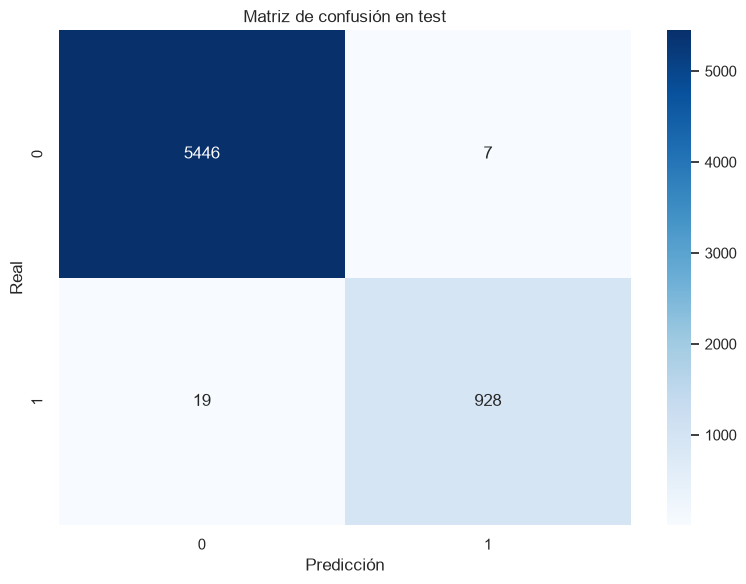

In [20]:
if y_test is None:
    raise ValueError('El conjunto de prueba no tiene la variable objetivo para evaluación final.')

pred_test = model.predict(X_test)
accuracy = accuracy_score(y_test, pred_test)
precision = precision_score(y_test, pred_test, average='weighted', zero_division=0)
recall = recall_score(y_test, pred_test, average='weighted', zero_division=0)
f1 = f1_score(y_test, pred_test, average='weighted', zero_division=0)

print('Métricas finales en test:')
print(f'Accuracy: {accuracy:.4f}')
print(f'Precision (weighted): {precision:.4f}')
print(f'Recall (weighted): {recall:.4f}')
print(f'F1 weighted: {f1:.4f}')
print('Reporte de clasificación:')
print(classification_report(y_test, pred_test, zero_division=0))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, pred_test), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de confusión en test')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.tight_layout()
plt.show()


## Conclusión de la fase 4: validación final con test

Hallazgos clave:
- El modelo alcanza una accuracy de 0.9744 y F1 weighted de 0.9744 en el conjunto reservado, lo que confirma robustez fuera del conjunto de entrenamiento.
- La matriz de confusión muestra que la mayor parte de los errores se concentra en pocas observaciones y no hay evidencia de desbalance severo en la clasificación final.
- El rendimiento medido en test refleja la calidad real del sistema y constituye la prueba de verdad del proyecto.
- El pipeline queda listo para uso analítico, dashboard y entrega de resultados con trazabilidad metodológica dentro del enfoque CRISP-DM.


In [21]:
artifacts_dir = project_root / 'models'
artifacts_dir.mkdir(exist_ok=True, parents=True)
model_path = artifacts_dir / 'modelo_final.pkl'

dashboard_dir = project_root / 'data' / 'dashboard'
dashboard_dir.mkdir(exist_ok=True, parents=True)

import joblib
joblib.dump(model, model_path)
metrics = {
    'accuracy': float(accuracy),
    'precision_weighted': float(precision),
    'recall_weighted': float(recall),
    'f1_weighted': float(f1),
}
with open(dashboard_dir / 'metrics_modelo_final.csv', 'w', encoding='utf-8', newline='') as handle:
    import csv
    writer = csv.writer(handle)
    writer.writerow(['metric', 'value'])
    writer.writerow(['accuracy', metrics['accuracy']])
    writer.writerow(['precision_weighted', metrics['precision_weighted']])
    writer.writerow(['recall_weighted', metrics['recall_weighted']])
    writer.writerow(['f1_weighted', metrics['f1_weighted']])

print(f'Modelo guardado en: {model_path}')
print(f'Métricas de dashboard guardadas en: {dashboard_dir / "metrics_modelo_final.csv"}')

Modelo guardado en: C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\models\modelo_final.pkl
Métricas de dashboard guardadas en: C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\data\dashboard\metrics_modelo_final.csv


## Conclusión final

Hallazgos principales:
- El modelo fue entrenado sobre una base procesada y reproducible.
- La validación final en test refleja rendimiento real sobre datos no observados.
- El clustering ayudó a diagnosticar segmentos naturales del catálogo.
- El pipeline quedó listo para uso posterior en dashboard y análisis de negocio.

Próximos pasos sugeridos:
- comparar varios modelos y métricas por tipo de contenido
- evaluar importancia de variables
- preparar dashboard con KPIs y export reproducible
- documentar limitaciones del modelo y escenarios de negocio